<a href="https://colab.research.google.com/github/jose-carrasco-e/proyecto-final/blob/main/proyecto_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import matplotlib.pyplot as mpl
from scipy.optimize import curve_fit

ecc lineal: 9.669801777170193*x + 170.30348598769658 R²: 0.9853
ecc cuadratica: -0.005160415686731978*x**2 + 10.056832953675078*x + 165.5301014774694 R²: 0.9854
ecc cubica: 0.002949012865687717*x**3 + -0.3369243630765024*x**2 + 19.94398838846077*x + 105.790473350882 R²: 0.9985
ecc coseno: 56.463320043680476*cos(0.4084949278458572*x + 33.352701456685566) + 532.9367232050478 R²: 0.0353


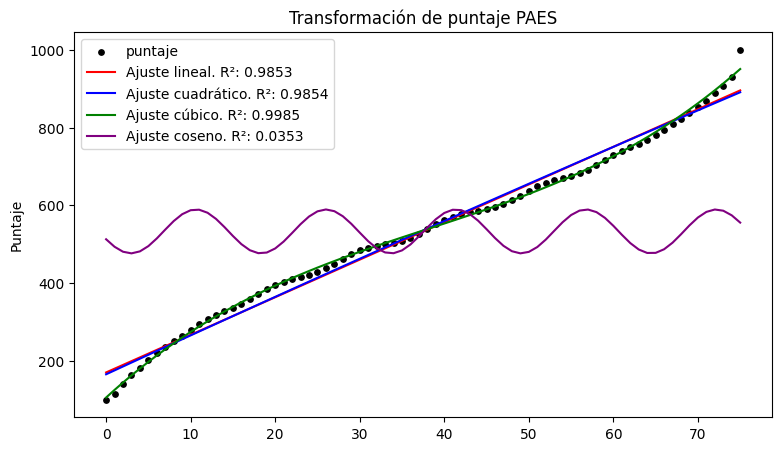

In [4]:
#i copied and pasted the table of scores from the pdf into a .txt file
datos = np.fromfile('/content/pauta.txt', dtype=int, sep=' ')
datos = datos.reshape(-1, 2)
#coupling the amount of correct answer with the corresponding score
datos = datos[datos[:, 0].argsort()]
#sorting the values so that it goes from 0 to 75 in order

np.save('pauta.npy', datos)
pauta = np.load('pauta.npy')

x = pauta[:, 0]
y = pauta[:, 1]

def lineal(x, a, b):
  return a*x + b

def cuadratica(x, a, b, c):
  return a*x**2 + b*x + c

def cubica(x, a, b, c, d):
  return a*x**3 + b*x**2 + c*x + d

def coseno(x, a, b, c, d):
  return a*np.cos(b*x + c) + d
#defining the equations that im gonna use for curve_fit

parametros_1, cov1 = curve_fit(lineal, x, y)
a, b = parametros_1

parametros_2, cov2 = curve_fit(cuadratica, x, y)
a, b, c = parametros_2

parametros_3, cov3 = curve_fit(cubica, x, y)
a, b, c, d = parametros_3

parametros_4, cov4 = curve_fit(coseno, x, y)
a, b, c, d = parametros_4


def r2(y, y_ajustado):
    SSres = np.sum((y - y_ajustado)**2)
    SStot = np.sum((y - np.mean(y))**2)

    return 1 - SSres/SStot

r2_lineal = r2(y, lineal(x, *parametros_1))
r2_cuadratica = r2(y, cuadratica(x, *parametros_2))
r2_cubica = r2(y, cubica(x, *parametros_3))
r2_coseno = r2(y, coseno(x, *parametros_4))
#seeing how accurate the functions are using R²

ecc_lineal = f"{parametros_1[0]}*x + {parametros_1[1]}"
ecc_cuadratica = f"{parametros_2[0]}*x**2 + {parametros_2[1]}*x + {parametros_2[2]}"
ecc_cubica = f"{parametros_3[0]}*x**3 + {parametros_3[1]}*x**2 + {parametros_3[2]}*x + {parametros_3[3]}"
ecc_coseno = f"{parametros_4[0]}*cos({parametros_4[1]}*x + {parametros_4[2]}) + {parametros_4[3]}"
#getting the final equation for the functions to then print them

print("ecc lineal:", ecc_lineal , "R²:", round(r2_lineal, 4))
print("ecc cuadratica:", ecc_cuadratica , "R²:", round(r2_cuadratica, 4))
print("ecc cubica:", ecc_cubica , "R²:", round(r2_cubica, 4))
print("ecc coseno:", ecc_coseno , "R²:", round(r2_coseno, 4))

mpl.figure(figsize=(9, 5))
mpl.scatter(x, y, s=15, label= 'puntaje', color='black')
mpl.plot(x, lineal(x, *parametros_1), label=f'Ajuste lineal. R²: {round(r2_lineal, 4)}', color='red')
mpl.plot(x, cuadratica(x, *parametros_2), label=f'Ajuste cuadrático. R²: {round(r2_cuadratica, 4)}', color='blue')
mpl.plot(x, cubica(x, *parametros_3), label=f'Ajuste cúbico. R²: {round(r2_cubica, 4)}', color='green')
mpl.plot(x, coseno(x, *parametros_4), label=f'Ajuste coseno. R²: {round(r2_coseno, 4)}', color='purple')
mpl.ylabel('Puntaje')
mpl.title('Transformación de puntaje PAES')
mpl.legend()
mpl.savefig('grafico_paes.png', bbox_inches='tight')
mpl.show()
